# Обработка естественного языка: NLP
## Токенизация, Word2Vec, RNN/LSTM, трансформеры, BERT и GPT

**Курс «Основы. Специалист по искусственному интеллекту» · Модуль 5**

Мы изучаем путь от строки текста к токенам, числовым представлениям и моделям последовательностей. Затем рассматриваем внимание и различие архитектур BERT и GPT. Общие понятия нейросетей, оптимизаторы, backpropagation, регуляризация, метрики и API PyTorch уже разобраны; здесь используем их для текста. Математических формул и выводов нет.

**Это материал с выполненными примерами, без заданий.** Перед каждым блоком кода дано введение, после — объяснение конструкций Python, параметров и результата. Ноутбук подходит для занятия и самостоятельного чтения.

### Среда и границы примеров

Используется ядро **«Python — основы фреймворков ИИ»** из материала № 12: Python 3.13, PyTorch 2.11.0, Transformers 5.3.0 и Tokenizers 0.22.2. Выберите **«Перезапустить ядро и выполнить все ячейки»** и запускайте файл из каталога курса.

Все тексты заданы внутри файла. Skip-gram, LSTM и компактные модели архитектур BERT и GPT обучаются прямо здесь на CPU. **Готовые предобученные языковые модели не загружаются.** Небольшие BERT и GPT в этом файле начинают со случайных весов: они показывают устройство и обучающую задачу, а не возможности большого предобученного ассистента. Их токенизатор тоже учебный, обученный локально; это не стандартные словари опубликованных BERT и GPT-2.

В установленной среде интернет для всех ячеек не требуется. Результаты создаются в папке `14_результаты_NLP`. Если нужно добавить библиотеки в среду материала № 12, отдельная команда PowerShell: `& "$env:USERPROFILE\.venvs\ai12\Scripts\python.exe" -m pip install "transformers==5.3.0" "tokenizers==0.22.2" "ipywidgets==8.1.9"`. `&` запускает указанный Python, `$env:USERPROFILE` подставляет домашнюю папку Windows, `-m pip install` запускает установку, `==` фиксирует версии. Пакет ipywidgets подготавливает служебные виджеты Jupyter; он устраняет предупреждение о недоступном IProgress. Сами ячейки не устанавливают пакеты.

Генерация длинных текстов, использование ChatGPT и промпт-инжиниринг относятся к модулю генеративного ИИ. Здесь для GPT рассматривается механизм предсказания следующего токена.

## 1. Текст, токены и словарь

**NLP, Natural Language Processing**, — обработка естественного языка. Среди задач: определение класса сообщения, поиск сущностей, перевод, ответы на вопросы, работа с языковыми представлениями. Формат выхода зависит от задачи: один класс для сообщения, метки отдельных фрагментов или последовательность токенов.

**Токенизация** делит текст на единицы обработки. Токен может быть словом, частью слова, знаком пунктуации или иным фрагментом. **Словарь** связывает допустимые токены с числовыми номерами, ID. Номер — индекс, а не значение слова: близкие номера не гарантируют близкого смысла.

Нормализация регистра и символов — отдельное решение. Например, приведение к нижнему регистру меняет представление имён и аббревиатур. Для уже обученной модели применяют именно её токенизатор и настройки; произвольная «очистка» перед ним может изменить ожидаемый вход.

Подключим инструменты и включим локальный режим Hugging Face. Модели будут создаваться из конфигураций, а при восстановлении читать только собственные файлы. Настроим CPU и вывод таблиц, затем покажем фактические версии.

In [1]:
import os
import sys
import re
import json
from pathlib import Path

os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['USE_TF'] = '0'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
import tokenizers
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers
import transformers
from transformers import BertConfig, BertForMaskedLM, GPT2Config, GPT2LMHeadModel
from transformers.utils import logging as hf_logging
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score
from IPython.display import display

torch.set_default_device('cpu')
torch.set_num_threads(1)
torch.manual_seed(23)
hf_logging.disable_progress_bar()
pd.set_option('display.precision', 4)
pd.set_option('display.max_colwidth', 70)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
result_dir = Path('14_результаты_NLP')
result_dir.mkdir(parents=True, exist_ok=True)

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('Transformers:', transformers.__version__, '| Tokenizers:', tokenizers.__version__)
print('Интерпретатор:', sys.executable)

Python: 3.13.13
PyTorch: 2.11.0+xpu
Transformers: 5.3.0 | Tokenizers: 0.22.2
Интерпретатор: C:\Users\user\.venvs\ai12\Scripts\python.exe


**Разбор кода и среды.**

- `import` подключает модуль, `from ... import ...` — отдельные инструменты, `as` даёт короткое имя. `re` работает с текстовыми шаблонами, `json` понадобится для описания результатов, `Path` — для файлов. NumPy, Pandas, Matplotlib и `display` дают массивы, таблицы и рисунки.
- `torch`, `nn` и `F` предоставляют сети и вычислительные функции. `pad_sequence` и `pack_padded_sequence` нужны для последовательностей разной длины. Tokenizers строит токенизатор, Transformers — архитектуры BERT и GPT. `CountVectorizer` покажет представление по частотам, `accuracy_score` — проверку классификатора.
- `os.environ[...]` задаёт строковые настройки до подключения библиотек. `HF_HUB_OFFLINE='1'` включает локальный режим Hub, `TOKENIZERS_PARALLELISM='false'` отключает параллельную обработку токенизатора. `USE_TF='0'` указывает использовать в этих примерах PyTorch.
- `torch.set_default_device('cpu')`, `set_num_threads(1)` и `manual_seed(23)` выбирают CPU, число потоков и начальное состояние случайного генератора. `hf_logging.disable_progress_bar()` выключает полосы прогресса Transformers, сохраняя сами вычисления и сообщения об ошибках.
- `pd.set_option(...)` управляет таблицами, `plt.rcParams[...]` — шрифтом и рисунками. `Path(...)` задаёт путь, `.mkdir(parents=True, exist_ok=True)` создаёт каталог с нужными родителями и допускает уже существующий.
- `print(...)`, `.__version__` и `sys.executable` показывают среду. `sys.version.split()[0]` делит строку версии на части и выбирает первую.

В этом процессе не вызываются сетевые сервисы языковых моделей. Все последующие веса будут получены локальным обучением или восстановлены из его результатов.

Сравним разбиение по пробелам с простым разбиением на слова, числа и пунктуацию. Для второго варианта также покажем позиции фрагментов в исходной строке. Это понятный начальный токенизатор, но у него нет правил конкретной большой языковой модели.

In [2]:
def word_tokens(text):
    return re.findall(r'\w+|[^\w\s]', text.lower())

sample_text = 'Привет, NLP! Модель читает 2 текста.'
simple_parts = sample_text.split()
matches = list(re.finditer(r'\w+|[^\w\s]', sample_text.lower()))
token_table = pd.DataFrame([
    {'Токен': match.group(), 'Начало': match.start(), 'Конец': match.end(),
     'Исходный фрагмент': sample_text[match.start():match.end()]}
    for match in matches
])
print('По пробелам:', simple_parts)
print('По правилу:', word_tokens(sample_text))
display(token_table)

По пробелам: ['Привет,', 'NLP!', 'Модель', 'читает', '2', 'текста.']
По правилу: ['привет', ',', 'nlp', '!', 'модель', 'читает', '2', 'текста', '.']


,Токен,Начало,Конец,Исходный фрагмент
0,привет,0,6,Привет
1,",",6,7,","
2,nlp,8,11,NLP
3,!,11,12,!
4,модель,13,19,Модель
5,читает,20,26,читает
6,2,27,28,2
7,текста,29,35,текста
8,.,35,36,.


**Разбор токенизации и позиций.**

- `def word_tokens(text):` определяет функцию, `return` возвращает результат. `text.lower()` приводит текст к нижнему регистру. `re.findall(...)` находит все совпадения: `\w+` — последовательность букв, цифр или подчёркиваний, `[^\w\s]` — отдельный символ, не относящийся к ним или к пробелам. `|` означает выбор одного из вариантов.
- Префикс `r` у строки сохраняет обратные слеши шаблона без дополнительной обработки Python. Регулярные выражения Python работают с русскими буквами; это не алгоритм понимания языка.
- `.split()` без аргументов делит строку по пробельным промежуткам, поэтому запятая остаётся рядом со словом. `re.finditer(...)` возвращает перебор совпадений с позициями; `list(...)` собирает его в список.
- `.group()` получает найденный токен, `.start()` и `.end()` — начало и конец. Срез `sample_text[start:end]` выбирает фрагмент с включённым началом и исключённым концом. В этой строке смена регистра сохраняет длины букв, поэтому позиции согласованы с оригиналом.
- Список словарей создаётся выражением `[... for match in matches]`. `pd.DataFrame(...)`, `display(...)` и `print(...)` показывают сравнение и таблицу.

Пунктуация стала отдельными токенами, а исходное написание видно рядом. Удалять слова вроде «не» или всю пунктуацию автоматически не следует: это способно изменить смысл задачи.

Зададим маленький авторский корпус и отдельную задачу коротких команд. У команды нужно определить первое действие. Обучающие и валидационные команды создадим по разным шаблонам: содержание операций знакомо, но сочетания служебных слов в валидации новые.

In [3]:
language_corpus = [
    'кот пьёт молоко', 'кот ест рыбу', 'кошка пьёт молоко', 'кошка ест рыбу',
    'пёс пьёт воду', 'пёс ест мясо', 'собака пьёт воду', 'собака ест мясо',
    'ученик читает книгу', 'студент читает книгу', 'робот читает текст', 'модель читает текст',
    'рыба живёт в воде', 'карась живёт в воде', 'птица строит гнездо', 'воробей строит гнездо',
]
actions = ['открыть', 'закрыть', 'включить', 'выключить']
train_templates = [
    'сначала {first} потом {second}', 'нужно сначала {first} потом {second}',
    'пожалуйста сначала {first} затем {second}', 'сначала {first} а затем {second}',
    'выполни сначала {first} и потом {second}', 'план сначала {first} после этого {second}',
    'сегодня сначала {first} затем {second}', 'команда сначала {first} потом {second}',
]
valid_templates = [
    'пожалуйста сначала {first} а потом {second}',
    'сегодня нужно сначала {first} после этого {second}',
]

def make_commands(templates):
    rows = []
    for template in templates:
        for first in actions:
            for second in actions:
                if first != second:
                    rows.append({'Текст': template.format(first=first, second=second),
                                 'Первое действие': first, 'Метка': actions.index(first)})
    return pd.DataFrame(rows)

train_commands = make_commands(train_templates)
valid_commands = make_commands(valid_templates)
print('Фраз корпуса:', len(language_corpus))
print('Команд: обучение', len(train_commands), '| валидация', len(valid_commands))
display(train_commands.head())

Фраз корпуса: 16
Команд: обучение 96 | валидация 24


,Текст,Первое действие,Метка
0,сначала открыть потом закрыть,открыть,0
1,сначала открыть потом включить,открыть,0
2,сначала открыть потом выключить,открыть,0
3,сначала закрыть потом открыть,закрыть,1
4,сначала закрыть потом включить,закрыть,1


**Разбор данных и шаблонов.**

- Квадратные скобки создают списки фраз, действий и шаблонов. В шаблоне `{first}` и `{second}` обозначают места подстановки. Фразы написаны для этого примера и не являются внешним датасетом.
- `def make_commands(templates):` создаёт функцию. `rows = []` задаёт список строк; три вложенных цикла `for` перебирают шаблоны и пары действий.
- `if first != second:` оставляет разные действия. Двоеточия и отступы определяют блоки. `template.format(first=..., second=...)` подставляет выбранные строки, `.append({...})` добавляет словарь новой команды.
- `actions.index(first)` находит номер первого действия в списке: от 0 до 3. Это наша метка класса; она отличается от ID токенов текста. `return pd.DataFrame(rows)` возвращает таблицу.
- Два вызова `make_commands(...)` обрабатывают разные шаблоны. `len(...)`, `print(...)`, `.head()` и `display(...)` показывают количество и первые строки.

Получаются 96 обучающих и 24 валидационные команды. Здесь нет окончательного тестового набора: валидация показывает результат заданного учебного опыта. Корпус из 16 фраз отдельно используется для представлений слов и маленьких языковых моделей.

### Подслова и служебные токены

Словарь только полных слов неудобен при редких словах и новых окончаниях. **Подсловная токенизация** может представить слово несколькими известными фрагментами. В **BPE** частые соседние элементы постепенно объединяются; список объединений определяется при обучении токенизатора.

Используем свой символьный BPE. Он обучается на корпусе и **обучающих** командах, без валидационных строк. Реальные BERT и GPT используют токенизаторы, связанные с конкретными весами; правила и служебные обозначения могут различаться. [Руководство Tokenizers](https://huggingface.co/docs/tokenizers/en/quicktour).

| Обозначение в этом файле | Назначение |
|---|---|
| `[PAD]` | Дополнение до общей длины пакета |
| `[UNK]` | Неизвестный элемент, который этот токенизатор не смог представить |
| `[CLS]`, `[SEP]` | Служебные границы входа примера BERT |
| `[MASK]` | Скрытый токен в задаче восстановления |
| `[BOS]`, `[EOS]` | Начало и конец последовательности примера GPT |

Обучим локальный BPE и посмотрим, как он разбивает знакомые слова и новое слово с другим окончанием. Выведем также поведение на незнакомом символе. Номера служебных токенов прочитаем из словаря, а не будем предполагать их вручную.

In [4]:
special_tokens = ['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]', '[BOS]', '[EOS]']
tokenizer = Tokenizer(models.BPE(unk_token='[UNK]'))
tokenizer.normalizer = normalizers.Sequence([normalizers.NFC(), normalizers.Lowercase()])
tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
bpe_trainer = trainers.BpeTrainer(
    vocab_size=256, min_frequency=1, show_progress=False, special_tokens=special_tokens
)
tokenizer_texts = language_corpus + train_commands['Текст'].tolist()
tokenizer.train_from_iterator(tokenizer_texts, trainer=bpe_trainer)
vocab_size = tokenizer.get_vocab_size()
special_ids = {token: tokenizer.token_to_id(token) for token in special_tokens}
pad_id = special_ids['[PAD]']

bpe_text = 'модель читает читателям'
bpe_encoding = tokenizer.encode(bpe_text)
display(pd.DataFrame({'Токен': bpe_encoding.tokens, 'ID': bpe_encoding.ids,
                     'Позиции в строке': bpe_encoding.offsets}))
print('Размер словаря:', vocab_size)
print('Служебные ID:', special_ids)
print('Незнакомый символ:', tokenizer.encode('модель 🙂').tokens)

,Токен,ID,Позиции в строке
0,модель,164,"(0, 6)"
1,читает,111,"(7, 13)"
2,чи,38,"(14, 16)"
3,т,25,"(16, 17)"
4,а,7,"(17, 18)"
5,те,61,"(18, 20)"
6,л,18,"(20, 21)"
7,я,34,"(21, 22)"
8,м,19,"(22, 23)"


Размер словаря: 174
Служебные ID: {'[PAD]': 0, '[UNK]': 1, '[CLS]': 2, '[SEP]': 3, '[MASK]': 4, '[BOS]': 5, '[EOS]': 6}
Незнакомый символ: ['модель', '[UNK]']


**Разбор обучения BPE.**

- `Tokenizer(models.BPE(unk_token='[UNK]'))` создаёт объект и его модель разбиения. `normalizers.Sequence([...])` последовательно применяет `NFC()` для согласованного представления Unicode и `Lowercase()` для нижнего регистра. Это наши настройки, выбранные до обучения маленьких моделей.
- `pre_tokenizers.Whitespace()` предварительно разделяет текст по правилам пробелов и пунктуации. BPE изучает объединения внутри полученных частей. `trainers.BpeTrainer(...)` задаёт верхнюю границу `vocab_size`, минимальную частоту, отключение полосы прогресса и список служебных токенов.
- Оператор `+` соединяет два списка строк, `.tolist()` получает список из столбца Pandas. `.train_from_iterator(..., trainer=...)` обучает токенизатор на этих текстах. Число 256 — ограничение, фактический словарь может быть меньше.
- `.get_vocab_size()` читает его размер. Словарное выражение `{token: ... for token in ...}` сопоставляет служебные строки их ID через `.token_to_id(...)`; `special_ids['[PAD]']` выбирает номер дополнения.
- `.encode(...)` возвращает объект разбиения. `.tokens`, `.ids` и `.offsets` содержат фрагменты, номера и позиции в исходной строке. `pd.DataFrame(...)`, `display(...)` и `print(...)` показывают их.

Известные частые слова здесь могут остаться целыми, новое слово делится на части. Наш символьный BPE способен вернуть `[UNK]` для нового символа. Это не универсальное поведение любого BPE: у байтовых вариантов другой способ покрытия символов.

В сохранённом запуске словарь содержит 174 токена вместе со служебными. Слово «читателям» разбилось на несколько известных фрагментов, а незнакомый символ 🙂 получил `[UNK]`. Это два разных случая: новое слово не обязательно целиком становится неизвестным.

Объединим тексты разной длины в пакет. Сохраним настоящую длину каждой последовательности и дополним короткие строки токеном `[PAD]`. Отдельно построим маску допустимых позиций: она понадобится трансформерам.

In [5]:
def encode_batch(texts):
    sequences = [torch.tensor(tokenizer.encode(text).ids, dtype=torch.long) for text in texts]
    lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
    token_ids = pad_sequence(sequences, batch_first=True, padding_value=pad_id)
    return token_ids, lengths

batch_texts = ['кот пьёт молоко', 'рыба живёт в воде', 'робот читает текст']
batch_ids, batch_lengths = encode_batch(batch_texts)
batch_attention_mask = batch_ids.ne(pad_id).long()
display(pd.DataFrame(batch_ids.numpy(), index=batch_texts))
print('Длины:', batch_lengths.tolist())
print('Маска допустимых позиций:')
display(pd.DataFrame(batch_attention_mask.numpy(), index=batch_texts))

,0,1,2,3
кот пьёт молоко,123,110,148,0
рыба живёт в воде,165,143,9,137
робот читает текст,166,111,135,0


Длины: [3, 4, 3]
Маска допустимых позиций:


,0,1,2,3
кот пьёт молоко,1,1,1,0
рыба живёт в воде,1,1,1,1
робот читает текст,1,1,1,0


**Разбор пакета и маски.**

- `def encode_batch(texts):` определяет функцию. Список `sequences` создаётся перебором текстов; `tokenizer.encode(text).ids` получает ID, `torch.tensor(..., dtype=torch.long)` — целочисленный тензор, подходящий для индексов.
- `len(sequence)` считает настоящие токены, второй `torch.tensor(...)` сохраняет длины. `pad_sequence(..., batch_first=True, padding_value=pad_id)` создаёт общий прямоугольный пакет: сначала строки объектов, затем позиции. Короткие строки справа дополняются нашим PAD.
- `return token_ids, lengths` возвращает два объекта. Запись `batch_ids, batch_lengths = ...` распаковывает их в две переменные.
- `.ne(pad_id)` проверяет неравенство дополнению, `.long()` превращает логические значения в 1 и 0. Здесь 1 означает настоящую позицию, 0 — дополнение. Именно такой смысл будет у `attention_mask` в примерах Hugging Face.
- `.numpy()`, `pd.DataFrame(..., index=...)`, `display(...)`, `.tolist()` и `print(...)` показывают пакет, длины и маску.

PAD позволяет хранить разную длину в одном тензоре, но не должен становиться содержательным словом. В этих примерах тексты короткие и не обрезаются. В реальной модели превышение предельной длины требует явного решения: обрезки, разбиения или иной обработки.

## 2. Векторизация: от ID к представлению

**Embedding, или эмбеддинг**, — плотный обучаемый вектор токена. Слой хранит таблицу: ID выбирает её строку. Сами числа вектора могут изменяться при обучении. Это нужно отличать от простой перенумерации словаря.

**Word2Vec** учит представления слов по соседним словам корпуса. Вариант **CBOW** предсказывает центральное слово по окружению, **Skip-gram** — контекстные слова по центральному. Такие векторы статические: одно слово получает одну строку таблицы независимо от конкретного предложения. [Работа о Word2Vec](https://arxiv.org/abs/1301.3781).

Ниже реализуем небольшой **учебный Skip-gram**. Для маленького словаря предсказываем контекст по всем словам сразу. Практические реализации Word2Vec используют более экономные способы, например negative sampling; настройку и математику этой оптимизации здесь не разбираем. Пример обучает реальные векторы по соседствам, но его крошечный корпус не заменяет большие предобученные представления.

Сначала создадим обычную таблицу эмбеддингов для BPE-словаря и применим её к пакету. Она пока не обучена: рассматриваем только переход от ID к векторам и поведение строки PAD.

In [6]:
torch.manual_seed(19)
embedding_demo = nn.Embedding(vocab_size, 16, padding_idx=pad_id)
with torch.no_grad():
    embedded_batch = embedding_demo(batch_ids)
print('Форма ID:', tuple(batch_ids.shape))
print('Форма векторов:', tuple(embedded_batch.shape))
print('Вектор PAD нулевой:', torch.equal(embedding_demo.weight[pad_id], torch.zeros(16)))
display(pd.DataFrame(embedded_batch[0, :, :6].numpy(), index=tokenizer.encode(batch_texts[0]).tokens + ['[PAD]']))

Форма ID: (3, 4)
Форма векторов: (3, 4, 16)
Вектор PAD нулевой: True


,0,1,2,3,4,5
кот,2.3008,0.4232,-0.5313,-1.8489,0.4746,0.0178
пьёт,-0.2933,1.4992,-0.3765,-0.2383,1.1494,0.3284
молоко,0.5448,0.8062,1.0707,-0.4449,0.9571,-2.6664
[PAD],0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


**Разбор таблицы эмбеддингов.**

- `torch.manual_seed(19)` фиксирует создание случайной таблицы. `nn.Embedding(vocab_size, 16, padding_idx=pad_id)` выделяет по 16 чисел на каждый ID. `padding_idx` помечает строку дополнения: при обычном создании она нулевая и не обучается через этот слой.
- В `torch.no_grad()` вызов `embedding_demo(batch_ids)` выбирает векторы сразу для всего пакета. На выходе три оси: объекты, позиции, признаки токена. ID не умножается на «важность слова», а выбирает строку таблицы.
- `.shape`, `tuple(...)` и `print(...)` показывают добавленную размерность. `.weight[pad_id]` читает строку PAD, `torch.zeros(16)` создаёт нулевой эталон, `torch.equal(...)` проверяет точное совпадение.
- `[0, :, :6]` выбирает первое предложение, все его позиции и первые шесть признаков. `.numpy()`, `pd.DataFrame(...)` и `display(...)` показывают числа. `tokenizer.encode(...).tokens + ['[PAD]']` подписывает три настоящих токена и одну дополнительную позицию данного пакета.

У случайных векторов пока нет изученного языкового смысла. Даже нулевой PAD не гарантирует, что последующие слои проигнорируют эту позицию: для последовательностей нужны длины или маска, как будет показано далее.

Подготовим пары Skip-gram из корпуса: одно центральное слово и одно слово его окружения. Возьмём соседей не дальше двух позиций, не выходя за границы предложения. Здесь используется отдельный словарь полных слов; его ID не смешиваются с ID токенизатора BPE.

In [7]:
word_sentences = [word_tokens(text) for text in language_corpus]
word_vocabulary = sorted({word for sentence in word_sentences for word in sentence})
word_to_id = {word: index for index, word in enumerate(word_vocabulary)}
word_pairs = []
for sentence in word_sentences:
    for center_position, center_word in enumerate(sentence):
        left = max(0, center_position - 2)
        right = min(len(sentence), center_position + 3)
        for context_position in range(left, right):
            if context_position != center_position:
                word_pairs.append((word_to_id[center_word], word_to_id[sentence[context_position]]))
pair_tensor = torch.tensor(word_pairs, dtype=torch.long)
display(pd.DataFrame([
    {'Центральное слово': word_vocabulary[center], 'Контекстное слово': word_vocabulary[context]}
    for center, context in word_pairs[:10]
]))
print('Слов в словаре:', len(word_vocabulary), '| пар:', len(word_pairs))

,Центральное слово,Контекстное слово
0,кот,пьёт
1,кот,молоко
2,пьёт,кот
3,пьёт,молоко
4,молоко,кот
5,молоко,пьёт
6,кот,ест
7,кот,рыбу
8,ест,кот
9,ест,рыбу


Слов в словаре: 26 | пар: 104


**Разбор пар контекста.**

- `[word_tokens(text) for text in language_corpus]` токенизирует каждую фразу. Множество `{word for sentence in ... for word in ...}` собирает уникальные слова, `sorted(...)` упорядочивает их для стабильных ID.
- Словарь `{word: index for index, word in enumerate(...)}` связывает слова с номерами. Это отдельная таблица именно этого Skip-gram; одинаковое слово в BPE может иметь другой номер.
- Циклы `for` перебирают предложения и позиции. `max(0, center_position - 2)` ограничивает левую границу, `min(len(sentence), center_position + 3)` — правую. `range(left, right)` не включает правую границу, поэтому охватывает не более двух соседей с каждой стороны.
- `if context_position != center_position` исключает саму центральную позицию. `.append((..., ...))` добавляет кортеж двух ID; вложенные квадратные скобки получают контекстное слово, затем его номер.
- `torch.tensor(..., dtype=torch.long)` создаёт тензор пар. Срез `[:10]`, `pd.DataFrame(...)` и `display(...)` показывают первые пары в читаемом виде; `len(...)` и `print(...)` — размеры.

Одно центральное слово образует несколько обучающих пар. Повторяющиеся соседства — полезная информация корпуса; они не превращаются в независимые сведения о значении слова вне этих примеров.

Обучим Skip-gram: входная таблица выдаст вектор центрального слова, а выходной слой будет предсказывать контекст. После обучения будем использовать именно входные векторы. Все 250 эпох заданы заранее, без подбора по таблице соседей.

In [8]:
class SkipGram(nn.Module):
    def __init__(self, word_count, vector_size=16):
        super().__init__()
        self.input_vectors = nn.Embedding(word_count, vector_size)
        self.context_head = nn.Linear(vector_size, word_count, bias=False)

    def forward(self, center_ids):
        return self.context_head(self.input_vectors(center_ids))

torch.manual_seed(23)
skipgram_model = SkipGram(len(word_vocabulary))
skipgram_optimizer = torch.optim.Adam(skipgram_model.parameters(), lr=0.03)
skipgram_criterion = nn.CrossEntropyLoss()
skipgram_history_rows = []
for epoch in range(1, 251):
    skipgram_optimizer.zero_grad(set_to_none=True)
    context_logits = skipgram_model(pair_tensor[:, 0])
    skipgram_loss = skipgram_criterion(context_logits, pair_tensor[:, 1])
    skipgram_loss.backward()
    skipgram_optimizer.step()
    skipgram_history_rows.append({'Эпоха': epoch, 'Потеря': skipgram_loss.item()})
skipgram_model.eval()
word_vectors = skipgram_model.input_vectors.weight.detach().clone()
skipgram_history = pd.DataFrame(skipgram_history_rows).set_index('Эпоха')
display(skipgram_history.loc[[1, 50, 150, 250]])

,Потеря
Эпоха,
1,3.5028
50,1.2250
150,1.2209
250,1.2204


**Разбор обучения Skip-gram.**

- `class SkipGram(nn.Module)` определяет модуль. `def __init__(self, ...)`, `super().__init__()` и атрибуты `self...` создают его части. `nn.Embedding(...)` хранит входные векторы, `nn.Linear(..., bias=False)` выдаёт логиты всех контекстных слов.
- В `forward` внутренний вызов `self.input_vectors(center_ids)` получает векторы, `self.context_head(...)` предсказывает контекст; `return` возвращает выход. `SkipGram(len(...))` создаёт объект с размером текущего словаря, `torch.manual_seed(23)` фиксирует начальные веса.
- `torch.optim.Adam(...parameters(), lr=0.03)` создаёт оптимизатор. `nn.CrossEntropyLoss()` создаёт функцию потерь; вызов `skipgram_criterion(...)` получает логиты словаря и правильные контекстные ID. `pair_tensor[:, 0]` выбирает все центральные слова, `[:, 1]` — соответствующие контекстные.
- `range(1, 251)` задаёт эпохи. `zero_grad(set_to_none=True)`, вызов `skipgram_model(...)`, `backward()` и `step()` выполняют уже знакомый шаг обучения. Маленький набор пар обрабатывается целиком.
- `.item()` извлекает потерю, `.append({...})` записывает историю. `.eval()` задаёт проверочный режим. `.weight.detach().clone()` делает независимую копию обученных входных векторов без графа.
- `pd.DataFrame(...).set_index(...)`, `.loc[[...]]` и `display(...)` показывают выбранные эпохи.

Вектор изучался через предсказание соседей, а не через выданный человеком список синонимов. У одного слова может быть несколько правильных соседей, поэтому не нужно ожидать нулевой потери или единственного однозначного контекста.

Получены векторы для 26 слов по 104 обучающим парам. После 250 эпох потеря около 1,2204. Номера слов этой таблицы и номера BPE остаются независимыми даже при совпадении текстового написания.

Найдём ближайшие векторы к слову «кот» и покажем сходство нескольких выбранных слов. Используем готовую функцию косинусного сходства без вывода формулы. На таком маленьком корпусе соседство нужно читать как результат именно этих фраз, а не как универсальный словарь смыслов.

,Слово,Сходство с «кот»
0,кошка,0.5457
1,модель,0.3509
2,пёс,0.3388
3,рыбу,0.3354
4,ест,0.3199


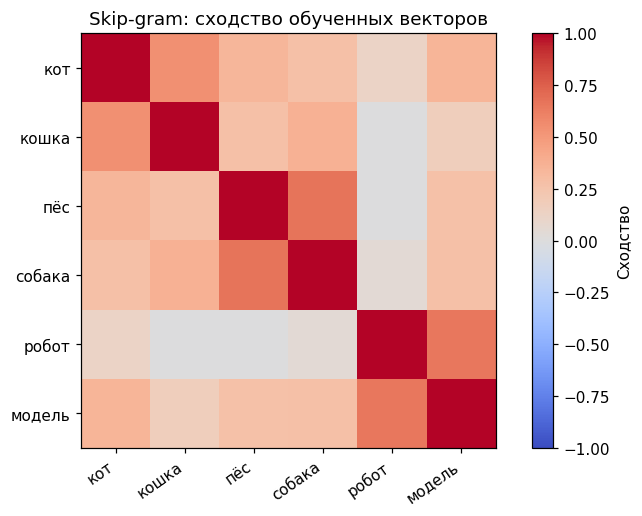

In [9]:
query_word = 'кот'
query_vector = word_vectors[word_to_id[query_word]]
word_similarities = F.cosine_similarity(word_vectors, query_vector.unsqueeze(0), dim=1)
word_similarities[word_to_id[query_word]] = float('-inf')
top_scores, top_indices = torch.topk(word_similarities, k=5)
neighbor_table = pd.DataFrame({'Слово': [word_vocabulary[index] for index in top_indices.tolist()],
                               'Сходство с «кот»': top_scores.numpy()})
display(neighbor_table)

selected_words = ['кот', 'кошка', 'пёс', 'собака', 'робот', 'модель']
selected_vectors = word_vectors[[word_to_id[word] for word in selected_words]]
similarity_matrix = torch.stack([
    F.cosine_similarity(selected_vectors, vector.unsqueeze(0), dim=1) for vector in selected_vectors
]).numpy()
fig, ax = plt.subplots(figsize=(7, 4.8))
heatmap = ax.imshow(similarity_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(selected_words)), labels=selected_words, rotation=35, ha='right')
ax.set_yticks(range(len(selected_words)), labels=selected_words)
ax.set_title('Skip-gram: сходство обученных векторов')
fig.colorbar(heatmap, ax=ax, label='Сходство')
fig.tight_layout()
plt.show()

**Разбор соседей и карты сходства.**

- `word_to_id[query_word]` выбирает строку нужного слова. `F.cosine_similarity(..., dim=1)` сравнивает векторы по оси признаков. `.unsqueeze(0)` добавляет ось для согласования форм при сравнении со всеми словами.
- Само слово исключается присваиванием `float('-inf')` его позиции: отрицательная бесконечность не попадёт в наибольшие значения. `torch.topk(..., k=5)` возвращает пять оценок и соответствующие индексы.
- `.tolist()` превращает индексы в список; списковое выражение выбирает слова. `.numpy()`, `pd.DataFrame(...)` и `display(...)` показывают соседей.
- Список `selected_words` задаёт показанные слова. Вложенный выбор `word_vectors[[...]]` получает их строки. `torch.stack([...])` собирает попарные результаты сравнения в таблицу.
- `plt.subplots(...)` создаёт рисунок, `imshow(...)` показывает карту с фиксированным диапазоном от −1 до 1. `set_xticks(...)`, `set_yticks(...)`, `range(...)` и `len(...)` подписывают позиции; `rotation` и `ha` задают читаемый наклон подписей.
- `set_title(...)`, `fig.colorbar(...)`, `tight_layout()` и `plt.show()` оформляют карту и шкалу.

Близость векторов отражает изученные контексты и выбранный способ сравнения. Статический Word2Vec не выдаёт отдельный вектор одного слова для каждого его значения: например, разные употребления многозначного слова смешивались бы в одной строке. Для незнакомого слова в этом словаре вообще нет готовой строки.

Ближайшим соседом «кот» в этом запуске стала «кошка» со сходством около 0,546. Следом встречается и «модель», что хорошо показывает ограничение маленького корпуса и выбранных векторов: это не готовая энциклопедическая шкала смысловой близости.

## 3. Порядок токенов и рекуррентные сети

Представление **мешка слов** хранит состав или частоты токенов, но теряет их порядок. В командах «сначала открыть потом закрыть» и «сначала закрыть потом открыть» набор слов одинаков, а первое действие разное.

**RNN** последовательно обрабатывает позиции и передаёт скрытое состояние следующему шагу. В **LSTM** дополнительно используется состояние памяти, а управляющие механизмы определяют, какую информацию сохранять, обновлять и выдавать. Это помогает работать с зависимостями в последовательности, но не гарантирует безошибочную память на любой длине.

Здесь покажем формы обычной RNN и LSTM, затем обучим один классификатор LSTM. Сравнение качества архитектур не проводится. Для справки: [RNN](https://docs.pytorch.org/docs/2.11/generated/torch.nn.RNN.html), [LSTM](https://docs.pytorch.org/docs/2.11/generated/torch.nn.LSTM.html).

Проверим потерю порядка на двух командах с одинаковыми словами. Построим счётчики токенов и сравним их строки. Этот небольшой отдельный пример векторизации не обучает классификатор и не меняет словари наших нейросетей.

In [10]:
order_texts = ['сначала открыть потом закрыть', 'сначала закрыть потом открыть']
count_vectorizer = CountVectorizer(tokenizer=word_tokens, token_pattern=None, lowercase=False)
count_matrix = count_vectorizer.fit_transform(order_texts).toarray()
display(pd.DataFrame(count_matrix, columns=count_vectorizer.get_feature_names_out(), index=order_texts))
print('Счётчики одинаковы:', np.array_equal(count_matrix[0], count_matrix[1]))

,закрыть,открыть,потом,сначала
сначала открыть потом закрыть,1,1,1,1
сначала закрыть потом открыть,1,1,1,1


Счётчики одинаковы: True


**Разбор представления без порядка.**

- `order_texts` — список двух строк. `CountVectorizer(...)` создаёт счётчик; `tokenizer=word_tokens` передаёт нашу функцию, `token_pattern=None` отключает альтернативный встроенный шаблон. `lowercase=False` не дублирует смену регистра, уже выполненную внутри функции.
- `.fit_transform(...)` изучает словарь этого примера и считает токены. `.toarray()` получает обычный плотный массив маленькой таблицы. У больших текстовых данных исходное разреженное представление обычно сохраняют ради памяти.
- `.get_feature_names_out()` возвращает имена столбцов, `pd.DataFrame(...)` подписывает строки, `display(...)` показывает частоты.
- `[0]` и `[1]` выбирают две строки, `np.array_equal(...)` сравнивает их, `print(...)` выводит результат.

Получается `True`, хотя метки первого действия различаются. По одним таким счётчикам нельзя отличить эти две команды. Для задачи нужен способ учитывать порядок.

Передадим обе команды в обычную RNN и LSTM. У этих строк одинаковая длина, поэтому в данном отдельном проходе padding не мешает чтению последнего состояния. Используем пока случайные эмбеддинги и сети: проверяем интерфейс и зависимость от порядка, а не обученные ответы.

In [11]:
order_ids, order_lengths = encode_batch(order_texts)
torch.manual_seed(29)
rnn_demo = nn.RNN(input_size=16, hidden_size=20, batch_first=True)
lstm_demo = nn.LSTM(input_size=16, hidden_size=20, batch_first=True)
with torch.no_grad():
    order_embeddings = embedding_demo(order_ids)
    rnn_outputs, rnn_hidden = rnn_demo(order_embeddings)
    lstm_outputs, (lstm_hidden, lstm_cell) = lstm_demo(order_embeddings)
print('RNN: выходы', tuple(rnn_outputs.shape), '| последнее состояние', tuple(rnn_hidden.shape))
print('LSTM: выходы', tuple(lstm_outputs.shape), '| hidden', tuple(lstm_hidden.shape), '| cell', tuple(lstm_cell.shape))
print('RNN различила порядок в состоянии:', not torch.allclose(rnn_hidden[:, 0], rnn_hidden[:, 1]))

RNN: выходы (2, 4, 20) | последнее состояние (1, 2, 20)
LSTM: выходы (2, 4, 20) | hidden (1, 2, 20) | cell (1, 2, 20)
RNN различила порядок в состоянии: True


**Разбор последовательных состояний.**

- `encode_batch(...)` получает ID и длины двух команд. `torch.manual_seed(29)` фиксирует создание демонстрационных модулей. `nn.RNN(...)` и `nn.LSTM(...)` принимают векторы из 16 признаков, хранят скрытое состояние размера 20; `batch_first=True` задаёт порядок «объекты, позиции, признаки» у входа и последовательных выходов.
- В `torch.no_grad()` вызов `embedding_demo(...)` выбирает векторы, затем `rnn_demo(...)` и `lstm_demo(...)` последовательно обрабатывают их. Эти таблица и модули не обучались в примере Skip-gram: у них собственные веса и BPE-ID.
- Записи с несколькими переменными распаковывают результаты. RNN возвращает выход для каждой позиции и итоговое скрытое состояние. LSTM возвращает также `cell`, отдельное состояние памяти. Начальные состояния не переданы: библиотека начинает с нулей.
- При одном слое и одном направлении последовательный выход имеет форму `(2, 4, 20)`, а итоговые состояния — `(1, 2, 20)`. Даже при `batch_first=True` итоговые состояния сохраняют порядок «слои и направления, объекты, признаки».
- `[:, 0]` и `[:, 1]` выбирают состояния двух строк. `torch.allclose(...)` проверяет их близость, `not` меняет ответ на противоположный. `.shape`, `tuple(...)` и `print(...)` показывают сведения.

Разные состояния ещё не означают правильного понимания команд. Они показывают, что архитектура может различать порядок, в отличие от предыдущей одинаковой строки частот. Научить нужному выходу предстоит отдельно.

Создадим классификатор LSTM для команд разной длины. Внутри будем упаковывать только настоящие позиции, чтобы модель не принимала хвост PAD за продолжение команды. Эмбеддинги этого классификатора обучаются с нуля вместе с ним; векторы Skip-gram в него не переносятся.

In [12]:
train_ids, train_lengths = encode_batch(train_commands['Текст'].tolist())
valid_ids, valid_lengths = encode_batch(valid_commands['Текст'].tolist())
train_labels = torch.tensor(train_commands['Метка'].to_numpy(), dtype=torch.long)
valid_labels = torch.tensor(valid_commands['Метка'].to_numpy(), dtype=torch.long)

class CommandLSTM(nn.Module):
    def __init__(self, vocabulary_size, padding_id):
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, 16, padding_idx=padding_id)
        self.sequence = nn.LSTM(16, 24, batch_first=True)
        self.classifier = nn.Linear(24, len(actions))

    def forward(self, input_ids, lengths):
        embeddings = self.embedding(input_ids)
        packed = pack_padded_sequence(embeddings, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, cell) = self.sequence(packed)
        return self.classifier(hidden[-1])

torch.manual_seed(31)
command_model = CommandLSTM(vocab_size, pad_id)
print('Обучающий пакет:', tuple(train_ids.shape))
print('Параметров:', sum(parameter.numel() for parameter in command_model.parameters()))

Обучающий пакет: (96, 6)
Параметров: 6916


**Разбор классификатора и настоящих длин.**

- `encode_batch(...)` получает пакеты и длины. `.tolist()` извлекает тексты, `.to_numpy()` — метки столбца; `torch.tensor(..., dtype=torch.long)` создаёт целочисленные ответы четырёх классов.
- `class CommandLSTM(nn.Module)`, `def __init__`, `self` и `super().__init__()` задают модуль. `nn.Embedding(...)` создаёт его собственные 16-мерные векторы, `nn.LSTM(...)` — скрытые состояния размера 24, `nn.Linear(24, len(actions))` — четыре выходных логита.
- В `forward` вызов `self.embedding(input_ids)` получает векторы. `pack_padded_sequence(..., lengths.cpu(), batch_first=True, enforce_sorted=False)` упаковывает только позиции в пределах настоящей длины. Длины должны находиться на CPU; `enforce_sorted=False` позволяет не сортировать наш пакет заранее.
- `self.sequence(packed)` возвращает итоговые состояния без чтения хвоста PAD. `_` принимает неиспользуемую последовательность выходов; `hidden[-1]` выбирает последний слой. `return self.classifier(...)` получает класс команды по итоговому состоянию. В этой однонаправленной однослойной сети это состояние после последнего настоящего токена.
- `torch.manual_seed(31)` фиксирует веса, `CommandLSTM(...)` создаёт объект. `.parameters()`, `.numel()` и `sum(...)` считают параметры; `.shape`, `tuple(...)` и `print(...)` показывают размер.

Одной нулевой строки PAD было бы недостаточно: рекуррентный слой мог бы продолжать менять состояние и на ней. Упаковка явно сообщает, где каждая команда закончилась. [Справка `pack_padded_sequence`](https://docs.pytorch.org/docs/2.11/generated/torch.nn.utils.rnn.pack_padded_sequence.html).

Обучим классификатор на 96 командах. Маленький пакет целиком помещается в памяти, поэтому здесь не нужен отдельный DataLoader. Сохраним потерю по эпохам; 100 эпох и шаг заданы до просмотра валидационных ответов.

In [13]:
command_optimizer = torch.optim.Adam(command_model.parameters(), lr=0.02)
command_criterion = nn.CrossEntropyLoss()
command_history_rows = []
for epoch in range(1, 101):
    command_model.train()
    command_optimizer.zero_grad(set_to_none=True)
    command_logits = command_model(train_ids, train_lengths)
    command_loss = command_criterion(command_logits, train_labels)
    command_loss.backward()
    command_optimizer.step()
    command_history_rows.append({'Эпоха': epoch, 'Потеря': command_loss.item()})
command_model.eval()
command_history = pd.DataFrame(command_history_rows).set_index('Эпоха')
display(command_history.loc[[1, 20, 50, 100]])

,Потеря
Эпоха,
1,1.3893e+00
20,3.4859e-03
50,1.2639e-04
100,7.4483e-05


**Разбор обучения команды.**

- `torch.optim.Adam(command_model.parameters(), lr=0.02)` выбирает все параметры этого классификатора. `nn.CrossEntropyLoss()` сопоставляет четыре логита с целочисленным номером первого действия.
- `command_history_rows = []` хранит историю. `range(1, 101)` задаёт 100 эпох, `.train()` включает обучающий режим.
- `zero_grad(set_to_none=True)` очищает прежние градиенты. Вызов `command_model(train_ids, train_lengths)` получает одновременно ID и настоящие длины, а `command_criterion(...)` сравнивает выходы с `train_labels`. `backward()` вычисляет градиенты, `step()` изменяет веса.
- `.item()` извлекает число потери, `.append({...})` записывает эпоху. `.eval()` после цикла переводит модель в режим получения ответов.
- `pd.DataFrame(...).set_index(...)` создаёт таблицу истории, `.loc[[...]]` выбирает четыре эпохи, `display(...)` выводит её.

Правильное действие задаёт разметка команд, а не номер последнего токена. Валидационные тексты и метки в этот цикл не передаются.

Проверим модель на 24 командах новых шаблонов. Дополнительно добавим к пакету ещё несколько PAD и убедимся, что при сохранённых длинах ответы не меняются. Это проверка правильной обработки дополнения, а не ещё одно обучение.

In [14]:
with torch.no_grad():
    valid_command_logits = command_model(valid_ids, valid_lengths)
    command_predictions = valid_command_logits.argmax(dim=1).numpy()
    extra_padding = torch.full((len(valid_ids), 3), pad_id, dtype=torch.long)
    extended_ids = torch.cat([valid_ids, extra_padding], dim=1)
    extended_logits = command_model(extended_ids, valid_lengths)
command_accuracy = accuracy_score(valid_labels.numpy(), command_predictions)
command_result_table = valid_commands.copy()
command_result_table['Ответ модели'] = [actions[index] for index in command_predictions]
display(command_result_table[['Текст', 'Первое действие', 'Ответ модели']].head(8))
print('Accuracy новых шаблонов:', round(command_accuracy, 4))
print('Дополнительный PAD не изменил логиты:', torch.allclose(valid_command_logits, extended_logits))

,Текст,Первое действие,Ответ модели
0,пожалуйста сначала открыть а потом закрыть,открыть,открыть
1,пожалуйста сначала открыть а потом включить,открыть,открыть
2,пожалуйста сначала открыть а потом выключить,открыть,открыть
3,пожалуйста сначала закрыть а потом открыть,закрыть,закрыть
4,пожалуйста сначала закрыть а потом включить,закрыть,закрыть
5,пожалуйста сначала закрыть а потом выключить,закрыть,закрыть
6,пожалуйста сначала включить а потом открыть,включить,включить
7,пожалуйста сначала включить а потом закрыть,включить,включить


Accuracy новых шаблонов: 1.0
Дополнительный PAD не изменил логиты: True


**Разбор проверки LSTM.**

- В `torch.no_grad()` `command_model(...)` получает выходы без нового графа. Режим `eval` установлен после обучения. `.argmax(dim=1).numpy()` выбирает номера наибольших логитов по оси классов и готовит массив ответов.
- `torch.full((len(valid_ids), 3), pad_id, dtype=torch.long)` создаёт три дополнительных PAD для каждой строки. `torch.cat([...], dim=1)` добавляет их по оси позиций. В повторный вызов передаются **прежние настоящие длины**.
- `accuracy_score(valid_labels.numpy(), command_predictions)` считает знакомый показатель. `.copy()` создаёт отдельную таблицу; список `[actions[index] for index in ...]` переводит метки в названия действий.
- Вложенный список имён столбцов выбирает нужные поля, `.head(8)`, `display(...)`, `round(..., 4)` и `print(...)` оформляют вывод. `torch.allclose(...)` сравнивает логиты до и после добавления PAD.

Вторая проверка должна дать `True`: упакованная LSTM не читает лишние позиции. Результат классификации относится к коротким командам этого формата, а не к произвольным инструкциям на русском языке. Новые шаблоны здесь всё ещё используют знакомые действия и слова.

В этом запуске правильно определены 24 из 24 валидационных команд: accuracy равна 1,0. Слова и действия здесь знакомы, новые только шаблоны их соединения; такой результат не переносится автоматически на свободные человеческие инструкции.

## 4. Трансформеры: позиции и внимание

**Self-attention, или самовнимание**, позволяет позиции получать информацию от доступных позиций того же входа. Query, key и value — обучаемые представления для выбора и передачи информации. В **multi-head attention** несколько голов выполняют такие преобразования параллельно, затем результаты объединяются.

Внутри слоя внимание не проходит текст рекуррентно слева направо. Поэтому модели нужна информация о позиции токена. В учебном примере добавим обучаемые векторы позиций. В других архитектурах способ учёта позиции может отличаться.

Блок трансформера включает внимание и отдельное преобразование признаков каждой позиции, а также остаточные связи и нормализацию. Идея обходной связи знакома по ResNet; здесь она применяется к представлениям токенов. Механизм предложен в [работе Transformer](https://arxiv.org/abs/1706.03762).

### Маски решают разные задачи

| Маска | Зачем нужна |
|---|---|
| Маска дополнения | Не читать PAD как полезное содержимое |
| Причинная, causal mask | Не позволять позиции читать будущие токены |

Encoder может учитывать левый и правый контекст. Causal decoder на текущей позиции использует только доступный префикс. В исходной схеме encoder–decoder декодер также читает выход кодировщика через cross-attention. BERT и GPT далее используют разные части семейства этих идей.

Добавим позиционные векторы к одной короткой команде и выполним обычное самовнимание без ограничения будущих позиций. Модуль пока не обучен: будем изучать формы и доступность информации, а не искать в его весах объяснение смысла команды.

In [15]:
attention_ids, attention_lengths = encode_batch([order_texts[0]])
attention_tokens = tokenizer.encode(order_texts[0]).tokens
sequence_length = attention_ids.shape[1]
torch.manual_seed(37)
position_embedding = nn.Embedding(32, 16)
attention_layer = nn.MultiheadAttention(embed_dim=16, num_heads=2, dropout=0.0, batch_first=True)
attention_layer.eval()
position_ids = torch.arange(sequence_length).unsqueeze(0)
with torch.no_grad():
    attention_input = embedding_demo(attention_ids) + position_embedding(position_ids)
    full_attention_output, full_attention_weights = attention_layer(
        attention_input, attention_input, attention_input,
        need_weights=True, average_attn_weights=False,
    )
print('Представления:', tuple(attention_input.shape))
print('Выход внимания:', tuple(full_attention_output.shape))
print('Веса: пакет, головы, позиции запроса, позиции источника:', tuple(full_attention_weights.shape))

Представления: (1, 4, 16)
Выход внимания: (1, 4, 16)
Веса: пакет, головы, позиции запроса, позиции источника: (1, 2, 4, 4)


**Разбор позиционной информации и внимания.**

- `encode_batch(...)` получает одну команду, `.shape[1]` — число позиций. `tokenizer.encode(...).tokens` сохраняет подписи. `torch.manual_seed(37)` фиксирует создание демонстрационных слоёв.
- `nn.Embedding(32, 16)` хранит векторы для позиций от 0 до 31. `torch.arange(sequence_length).unsqueeze(0)` создаёт строку их номеров. В `torch.no_grad()` `embedding_demo(...)` получает токеновые векторы, `position_embedding(...)` — позиционные; сложение соединяет два вида информации.
- `nn.MultiheadAttention(embed_dim=16, num_heads=2, dropout=0.0, batch_first=True)` задаёт две головы при общей размерности 16. `.eval()` выбирает проверочный режим; dropout отключён, чтобы отдельно рассмотреть веса внимания.
- Вызов `attention_layer(attention_input, attention_input, attention_input, ...)` передаёт один вход как query, key и value — это self-attention. Внутренние обучаемые преобразования выполняет сам слой.
- `need_weights=True` возвращает ещё и веса внимания, `average_attn_weights=False` сохраняет отдельную ось голов. Распаковка получает выход и веса. `.shape`, `tuple(...)` и `print(...)` показывают формы.

Получается выход `(1, 4, 16)` и веса `(1, 2, 4, 4)`. Это представления позиций, а не готовые названия действий. В готовых BERT и GPT позиционные преобразования выполняются внутри архитектуры: в них далее передаются ID, а не эти уже дополненные векторы.

На том же модуле запретим чтение будущих позиций и сравним карты внимания одной головы. Остальные веса и вход оставим теми же. Так видна роль причинной маски отдельно от обучения или смены архитектуры.

Будущие позиции получили нулевые веса: True


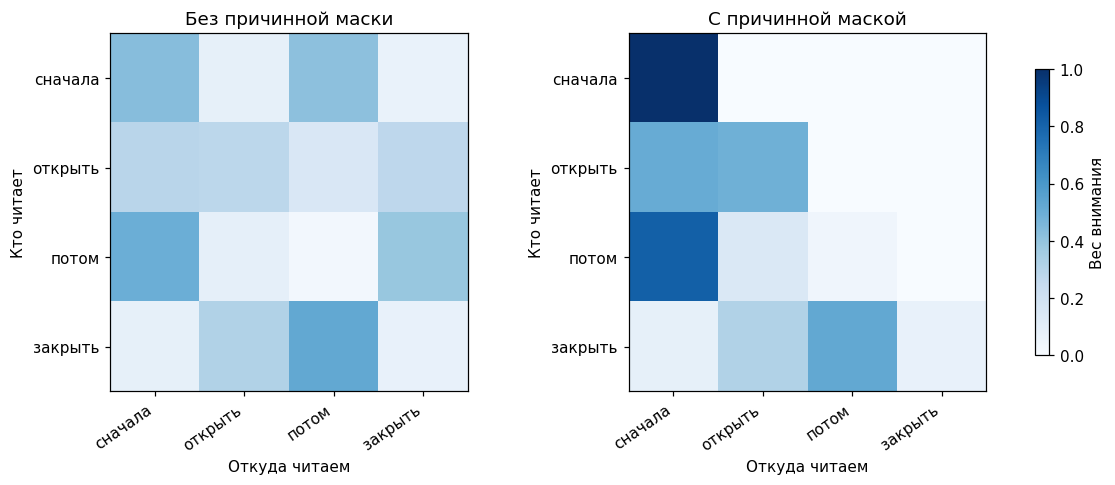

In [16]:
causal_mask = torch.triu(torch.ones(sequence_length, sequence_length, dtype=torch.bool), diagonal=1)
with torch.no_grad():
    causal_attention_output, causal_attention_weights = attention_layer(
        attention_input, attention_input, attention_input, attn_mask=causal_mask,
        need_weights=True, average_attn_weights=False,
    )
future_attention = causal_attention_weights[0, 0][causal_mask]
print('Будущие позиции получили нулевые веса:', bool(torch.all(future_attention == 0)))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3), layout='constrained')
for ax, weights, title in zip(
    axes, [full_attention_weights[0, 0], causal_attention_weights[0, 0]],
    ['Без причинной маски', 'С причинной маской'],
):
    image = ax.imshow(weights.numpy(), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(sequence_length), labels=attention_tokens, rotation=35, ha='right')
    ax.set_yticks(range(sequence_length), labels=attention_tokens)
    ax.set_xlabel('Откуда читаем')
    ax.set_ylabel('Кто читает')
    ax.set_title(title)
fig.colorbar(image, ax=axes, label='Вес внимания', shrink=0.8)
plt.show()

**Разбор причинной маски.**

- `torch.ones(..., dtype=torch.bool)` создаёт логическую матрицу. `torch.triu(..., diagonal=1)` оставляет верхнюю часть строго выше главной диагонали. Для **`nn.MultiheadAttention`** значение `True` в `attn_mask` означает запрет чтения соответствующей пары позиций.
- В `torch.no_grad()` `attention_layer(...)` получает прежние query, key и value, но дополнительно `attn_mask=causal_mask`. Флаги `need_weights` и `average_attn_weights` сохраняют тот же вид результата.
- `[0, 0]` выбирает первую строку пакета и первую голову. Следующий выбор `[causal_mask]` извлекает только запрещённые пары. `torch.all(... == 0)` проверяет все веса, `bool(...)` превращает ответ в обычное логическое значение, `print(...)` выводит его.
- `plt.subplots(..., layout='constrained')` создаёт две панели с автоматическим выделением места для подписей и общей шкалы; `zip(...)` согласованно перебирает панели, матрицы и подписи. `.numpy()`, `imshow(...)`, `set_xticks(...)`, `set_yticks(...)` и `range(...)` показывают карты с одинаковой шкалой и токенами.
- `set_xlabel(...)`, `set_ylabel(...)` и `set_title(...)` задают направления чтения. `fig.colorbar(...)` добавляет общую шкалу снаружи панелей; `shrink=0.8` уменьшает её высоту. `plt.show()` выводит рисунок.

Строка — читающая позиция, столбец — источник информации. Справа верхняя часть должна быть нулевой. Эта маска не заменяет маску PAD. Кроме того, смысл масок у разных API отличается: в `attention_mask` Hugging Face ниже 1, наоборот, означает разрешённую настоящую позицию.

Эти веса получены случайным необученным слоем и показывают действие ограничения. Даже у обученной модели одна карта внимания сама по себе не является полным объяснением её решения.

Выполним готовый блок Transformer Encoder, чтобы увидеть переход от отдельного внимания к полноценному блоку с преобразованием признаков. Передадим в него уже созданные токеновые и позиционные представления. Обучать этот демонстрационный блок не будем.

In [17]:
encoder_block = nn.TransformerEncoderLayer(
    d_model=16, nhead=2, dim_feedforward=32, dropout=0.0,
    activation='relu', batch_first=True,
)
encoder_block.eval()
with torch.no_grad():
    encoder_states = encoder_block(attention_input)
print('Форма входа блока:', tuple(attention_input.shape))
print('Форма выхода блока:', tuple(encoder_states.shape))

Форма входа блока: (1, 4, 16)
Форма выхода блока: (1, 4, 16)


**Разбор блока трансформера.**

- `nn.TransformerEncoderLayer(...)` создаёт один стандартный блок. `d_model=16` задаёт ширину представления, `nhead=2` — головы внимания, `dim_feedforward=32` — промежуточную ширину отдельного преобразования признаков.
- `dropout=0.0` выключает случайное зануление в этом примере, `activation='relu'` выбирает знакомую активацию, `batch_first=True` сохраняет порядок осей входа. Кроме внимания внутри есть остаточные связи и нормализация LayerNorm.
- `.eval()` и `torch.no_grad()` задают проверочное поведение и отключают новый граф. `encoder_block(attention_input)` выполняет блок на наших представлениях.
- `.shape`, `tuple(...)` и `print(...)` показывают, что число позиций и размерность представления сохранились.

Сохранение формы не означает сохранение исходных чисел: блок преобразовал представления. Это ещё не классификатор и не языковая модель. Для нужной задачи требуются обученные веса, соответствующее ограничение контекста и выходная часть.

## 5. BERT: двусторонний контекст и скрытый токен

**BERT** использует encoder-подобные блоки с доступом к левому и правому контексту. Одна из основных задач предобучения — **masked language modeling, MLM**: часть входных токенов скрывают, модель восстанавливает их по доступному окружению. В исходном BERT также была задача отношений предложений; здесь выполняется только маленький пример MLM. [Работа BERT](https://arxiv.org/abs/1810.04805).

У BERT выходное представление токена зависит от предложения. Прикладную задачу, например классификацию или выделение сущностей, задают соответствующей выходной частью и обучением. Служебный `[CLS]` не превращается в надёжный «вектор смысла» без подходящего обучения.

Ниже создаём **настоящую архитектуру `BertForMaskedLM` с очень маленькой конфигурацией и случайной инициализацией**. Её обучаем на наших 16 фразах. Это демонстрация устройства и запоминания конкретных связей, не оценка качества большой предобученной BERT. Токенизация у неё наша BPE, а не стандартный WordPiece исходного BERT.

Составим входы MLM: добавим `[CLS]` и `[SEP]`, скроем второй обычный токен каждой фразы и сохраним его правильный ID. Для остальных позиций поставим специальное значение игнорирования в разметке. Покажем согласование входа и цели на первой фразе.

In [18]:
cls_id = special_ids['[CLS]']
sep_id = special_ids['[SEP]']
mask_id = special_ids['[MASK]']
bert_sequences = [torch.tensor([cls_id] + tokenizer.encode(text).ids + [sep_id], dtype=torch.long)
                  for text in language_corpus]
bert_input_ids = pad_sequence(bert_sequences, batch_first=True, padding_value=pad_id)
bert_attention_mask = bert_input_ids.ne(pad_id).long()
bert_labels = torch.full_like(bert_input_ids, -100)
bert_labels[:, 2] = bert_input_ids[:, 2]
bert_input_ids[:, 2] = mask_id

display(pd.DataFrame({
    'Входной токен': [tokenizer.id_to_token(index) for index in bert_input_ids[0].tolist()],
    'Маска внимания': bert_attention_mask[0].tolist(),
    'Цель MLM': [tokenizer.id_to_token(index) if index != -100 else 'игнорируется'
                 for index in bert_labels[0].tolist()],
}))

,Входной токен,Маска внимания,Цель MLM
0,[CLS],1,игнорируется
1,кот,1,игнорируется
2,[MASK],1,пьёт
3,молоко,1,игнорируется
4,[SEP],1,игнорируется
5,[PAD],0,игнорируется


**Разбор входа и целей MLM.**

- `special_ids[...]` получает согласованные ID служебных токенов. Выражение `[cls_id] + tokenizer.encode(text).ids + [sep_id]` добавляет границы; `torch.tensor(..., dtype=torch.long)` создаёт строку ID для каждой фразы.
- `pad_sequence(..., batch_first=True, padding_value=pad_id)` собирает пакет. `.ne(pad_id).long()` создаёт `attention_mask`: 1 для настоящих позиций, 0 для PAD.
- `torch.full_like(bert_input_ids, -100)` создаёт разметку той же формы, заполненную значением игнорирования. Это **не ID словаря и не токен**: функция потерь не считает такие позиции.
- `[:, 2]` выбирает третью позицию во всех строках: после `[CLS]` это второй обычный токен. Сначала сохраняем правильные ID в `bert_labels`, затем заменяем их на `mask_id` во входе. Таким образом, ответ не остаётся на скрываемой позиции.
- `.tolist()` готовит обычные списки, `tokenizer.id_to_token(...)` переводит ID в понятные фрагменты. Условное выражение `... if index != -100 else ...` подписывает игнорируемые цели. `pd.DataFrame(...)` и `display(...)` показывают согласование.

В нашем корпусе частые слова представлены целыми токенами, поэтому скрывается слово вроде «пьёт». Для наглядности скрытая позиция фиксирована; полноценное предобучение использует гораздо более разнообразные данные и схему маскирования. Маска внимания и разметка потери решают разные задачи.

Создадим компактный BERT и обучим восстановление выбранных токенов. Один слой, небольшая ширина и короткий контекст делают пример быстрым на CPU. Модель создаётся из конфигурации: загрузки готовых весов здесь нет.

In [19]:
torch.manual_seed(41)
bert_config = BertConfig(
    vocab_size=vocab_size, hidden_size=32, num_hidden_layers=1,
    num_attention_heads=4, intermediate_size=64, max_position_embeddings=32,
    pad_token_id=pad_id, hidden_dropout_prob=0.0, attention_probs_dropout_prob=0.0,
)
bert_model = BertForMaskedLM(bert_config)
bert_optimizer = torch.optim.Adam(bert_model.parameters(), lr=0.01)
bert_history_rows = []
for epoch in range(1, 101):
    bert_model.train()
    bert_optimizer.zero_grad(set_to_none=True)
    bert_training_output = bert_model(
        input_ids=bert_input_ids, attention_mask=bert_attention_mask, labels=bert_labels
    )
    bert_loss = bert_training_output.loss
    bert_loss.backward()
    bert_optimizer.step()
    bert_history_rows.append({'Эпоха': epoch, 'Потеря': bert_loss.item()})
bert_model.eval()
bert_history = pd.DataFrame(bert_history_rows).set_index('Эпоха')
print('Параметров маленького BERT:', sum(parameter.numel() for parameter in bert_model.parameters()))
display(bert_history.loc[[1, 20, 50, 100]])

Параметров маленького BERT: 16558


,Потеря
Эпоха,
1,5.1009
20,1.5039
50,0.1527
100,0.0056


**Разбор конфигурации и обучения BERT.**

- `torch.manual_seed(41)` фиксирует создание модели. `BertConfig(...)` хранит архитектурные настройки: `vocab_size` согласован с нашим токенизатором, `hidden_size=32` задаёт ширину, `num_hidden_layers=1` — число блоков, `num_attention_heads=4` — головы, `intermediate_size=64` — внутреннее преобразование признаков.
- `max_position_embeddings=32` ограничивает позиции данного примера, `pad_token_id` указывает дополнение. Два параметра с `dropout_prob=0.0` отключают случайное зануление для прозрачного маленького опыта. Это настройки учебной модели, а не универсальная рекомендация.
- `BertForMaskedLM(bert_config)` создаёт веса с нуля и голову предсказания скрытого токена. `torch.optim.Adam(...parameters(), lr=0.01)` обучает все её параметры.
- `range(1, 101)`, `.train()` и `zero_grad(...)` организуют 100 эпох. Вызов `bert_model(...)` получает `input_ids`, `attention_mask` и `labels`; `.loss` возвращает потерю только для целей, не равных −100. `backward()` и `step()` выполняют обновление.
- `.item()` и `.append({...})` записывают историю, `.eval()` задаёт режим ответа. `pd.DataFrame(...).set_index(...)`, `.loc[[...]]` и `display(...)` показывают эпохи. `sum(...numel() for ...parameters())` и `print(...)` сообщают размер.

Все 16 фраз здесь обучающие. Уменьшение потери показывает освоение этой конкретной задачи, но не измеряет перенос на неизвестные тексты. Состав полей модели описан в [справке BERT для Transformers 5.3](https://huggingface.co/docs/transformers/v5.3.0/en/model_doc/bert).

Прочитаем предсказания на скрытых позициях и сравним их с сохранёнными словами. Покажем несколько обучающих фраз, а для первой — три наиболее высоко оценённых варианта. Это проверка, что маленькая модель действительно обучилась восстанавливать заданные связи.

In [20]:
with torch.no_grad():
    bert_final_logits = bert_model(input_ids=bert_input_ids, attention_mask=bert_attention_mask).logits
    bert_mask_predictions = bert_final_logits[:, 2].argmax(dim=1)
bert_example_table = pd.DataFrame({
    'Исходная фраза': language_corpus[:6],
    'Правильный токен': [tokenizer.id_to_token(index) for index in bert_labels[:6, 2].tolist()],
    'Ответ BERT': [tokenizer.id_to_token(index) for index in bert_mask_predictions[:6].tolist()],
})
display(bert_example_table)
bert_top_values, bert_top_indices = torch.softmax(bert_final_logits[0, 2], dim=0).topk(3)
display(pd.DataFrame({'Вариант первой маски': [tokenizer.id_to_token(index) for index in bert_top_indices.tolist()],
                     'Оценка': bert_top_values.numpy()}))

,Исходная фраза,Правильный токен,Ответ BERT
0,кот пьёт молоко,пьёт,пьёт
1,кот ест рыбу,ест,ест
2,кошка пьёт молоко,пьёт,пьёт
3,кошка ест рыбу,ест,ест
4,пёс пьёт воду,пьёт,пьёт
5,пёс ест мясо,ест,ест


,Вариант первой маски,Оценка
0,пьёт,0.9947
1,читает,0.0030
2,ест,0.0023


**Разбор предсказания скрытого токена.**

- В `torch.no_grad()` вызов `bert_model(...)` без `labels` возвращает выходы; `.logits` содержит оси «объекты, позиции, словарь». `[:, 2]` выбирает ранее скрытую позицию всех строк, `.argmax(dim=1)` — наибольший логит словаря для каждой.
- Срезы `[:6]` оставляют шесть примеров. `.tolist()` и `tokenizer.id_to_token(...)` переводят ответы и правильные ID в фрагменты текста; `pd.DataFrame(...)` и `display(...)` показывают их рядом с исходной фразой.
- `torch.softmax(bert_final_logits[0, 2], dim=0)` получает распределение оценок для одной маски. `.topk(3)` возвращает три наибольших значения и ID, которые распаковываются в две переменные. `.numpy()` готовит числа для второй таблицы.

Восстановление использует всё разрешённое окружение, включая слова справа. Таблица показывает знакомые обучающие случаи. По её совпадениям нельзя объявлять модель полноценным знатоком русского языка или измерять её качество на новых текстах.

Модель восстановила все 16 из 16 выбранных обучающих токенов. В первой строке наибольшую оценку получило «пьёт». Это подтверждает освоение известных примеров; независимая языковая валидация для этой маленькой MLM не проводилась.

Проверим контекстность представления слова «кот». В двух первых входах меняется слово справа от маски: «молоко» и «рыбу». Входной ID «кот» одинаков; сравним его исходные токеновые векторы и состояния после блока BERT.

In [21]:
with torch.no_grad():
    bert_context_ids = bert_input_ids[:2]
    bert_context_mask = bert_attention_mask[:2]
    bert_token_vectors = bert_model.get_input_embeddings()(bert_context_ids[:, 1])
    bert_context_states = bert_model.bert(
        input_ids=bert_context_ids, attention_mask=bert_context_mask
    ).last_hidden_state[:, 1]
print('Входные векторы одного ID одинаковы:', torch.allclose(bert_token_vectors[0], bert_token_vectors[1]))
print('Контекстные состояния одинаковы:', torch.allclose(bert_context_states[0], bert_context_states[1]))
display(pd.DataFrame(bert_context_states[:, :6].numpy(), index=['кот ... молоко', 'кот ... рыбу']))

Входные векторы одного ID одинаковы: True
Контекстные состояния одинаковы: False


,0,1,2,3,4,5
кот ... молоко,-0.2735,-0.2404,1.1926,-0.3440,-0.3886,0.4729
кот ... рыбу,-0.4356,-2.4963,1.5533,0.1258,-0.8764,0.5142


**Разбор контекстных состояний.**

- В `torch.no_grad()` срез `[:2]` выбирает первые две фразы с маской. `[:, 1]` — позиция «кот» после `[CLS]`. Это один ID в обоих входах.
- `bert_model.get_input_embeddings()` возвращает входной слой токеновых векторов; следующие круглые скобки вызывают его на выбранных ID. Без контекста одна и та же строка таблицы даёт одинаковые векторы.
- `bert_model.bert(...)` вызывает внутренний кодировщик без головы MLM. `.last_hidden_state` содержит состояния всех позиций последнего слоя, `[:, 1]` выбирает нужный токен после учёта окружения.
- `torch.allclose(...)` сравнивает пары векторов, `print(...)` выводит результаты. `[:, :6]`, `.numpy()`, `pd.DataFrame(..., index=...)` и `display(...)` показывают первые шесть числовых признаков.

Первая проверка даёт `True`, вторая — `False`. Одинаковая исходная строка токеновой таблицы преобразуется в разные состояния в разных контекстах. Отдельные координаты не подписаны человеческими понятиями: по одному числу нельзя назвать «смысл слова».

## 6. GPT: причинный контекст и следующий токен

**GPT** относится к семейству авторегрессионных языковых моделей. На каждой позиции модель предсказывает следующий токен по доступному префиксу. Будущие токены исключаются причинной маской. Архитектурный пример — [GPT-2](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf).

Цель для каждой позиции берётся из исходной строки: это следующий токен. Предыдущие настоящие токены подаются на вход; это ещё не самостоятельное развёртывание длинного ответа. И в MLM, и в предсказании следующего токена обучающие ответы формируются из самого текста, что называют самосупервизией. Благодаря причинной маске позиции одного обучающего примера могут обрабатываться параллельно без подглядывания в будущие ответы.

Создадим маленькую архитектуру `GPT2LMHeadModel` с нашим BPE-словарём. Она обучится только на 16 заданных фразах и не является предобученной GPT-2, ChatGPT или диалоговым ассистентом. Изменение размеров конфигурации не переносит знания больших моделей.

Подготовим последовательности с началом и концом. Явно сопоставим входные позиции с нужным следующим токеном и исключим цели PAD. Далее сдвиг сделаем вручную; `labels` в саму GPT передаваться не будут, чтобы не выполнить сдвиг повторно.

In [22]:
bos_id = special_ids['[BOS]']
eos_id = special_ids['[EOS]']
gpt_sequences = [torch.tensor([bos_id] + tokenizer.encode(text).ids + [eos_id], dtype=torch.long)
                 for text in language_corpus]
gpt_input_ids = pad_sequence(gpt_sequences, batch_first=True, padding_value=pad_id)
gpt_attention_mask = gpt_input_ids.ne(pad_id).long()
gpt_next_targets = gpt_input_ids[:, 1:].clone()
gpt_next_targets[gpt_attention_mask[:, 1:] == 0] = -100

display(pd.DataFrame({
    'Входная позиция': [tokenizer.id_to_token(index) for index in gpt_input_ids[0, :-1].tolist()],
    'Нужный следующий токен': [tokenizer.id_to_token(index) if index != -100 else 'игнорируется'
                              for index in gpt_next_targets[0].tolist()],
}))

,Входная позиция,Нужный следующий токен
0,[BOS],кот
1,кот,пьёт
2,пьёт,молоко
3,молоко,[EOS]
4,[EOS],игнорируется


**Разбор сдвига цели.**

- `special_ids[...]` выбирает начало и конец. `tokenizer.encode(text).ids` получает обычные токены; списки `[bos_id] + ... + [eos_id]` окружают их границами. `torch.tensor(..., dtype=torch.long)` создаёт последовательности. `pad_sequence(...)` объединяет их, `.ne(pad_id).long()` строит маску допустимого входа.
- `gpt_input_ids[:, 1:]` берёт токены со второй позиции: они станут целями для предыдущих. `.clone()` создаёт независимую разметку. Ей соответствует выход модели на позициях `[:, :-1]`, то есть на всех, кроме последней.
- Условие `gpt_attention_mask[:, 1:] == 0` выбирает цели дополнения, присваивание `-100` исключает их из потери. Токен `[EOS]` не равен PAD и остаётся настоящей целью: модель учится обозначать конец строки.
- `.tolist()`, `tokenizer.id_to_token(...)` и условное выражение переводят ID в подписи. `pd.DataFrame(...)` и `display(...)` показывают согласованные позиции.

У первого `[BOS]` цель — первое слово; у «пьёт» в первой фразе — «молоко». При использовании встроенного аргумента `labels` GPT может делать сдвиг сама. Здесь он показан явно и будет выполнен только один раз. [Справка GPT-2 для Transformers 5.3](https://huggingface.co/docs/transformers/v5.3.0/en/model_doc/gpt2).

Обучим компактную GPT предсказывать следующий токен по видимому префиксу. Модель сама применяет причинное ограничение; нашу маску PAD передадим отдельно. Потерю посчитаем по явно сдвинутым целям из предыдущего примера.

In [23]:
torch.manual_seed(43)
gpt_config = GPT2Config(
    vocab_size=vocab_size, n_positions=32, n_ctx=32, n_embd=32,
    n_layer=1, n_head=4, n_inner=64,
    bos_token_id=bos_id, eos_token_id=eos_id, pad_token_id=pad_id,
    attn_pdrop=0.0, resid_pdrop=0.0, embd_pdrop=0.0, use_cache=False,
)
gpt_model = GPT2LMHeadModel(gpt_config)
gpt_optimizer = torch.optim.Adam(gpt_model.parameters(), lr=0.01)
gpt_criterion = nn.CrossEntropyLoss(ignore_index=-100)
gpt_history_rows = []
for epoch in range(1, 121):
    gpt_model.train()
    gpt_optimizer.zero_grad(set_to_none=True)
    gpt_training_logits = gpt_model(input_ids=gpt_input_ids, attention_mask=gpt_attention_mask).logits
    gpt_loss = gpt_criterion(gpt_training_logits[:, :-1].reshape(-1, vocab_size), gpt_next_targets.reshape(-1))
    gpt_loss.backward()
    gpt_optimizer.step()
    gpt_history_rows.append({'Эпоха': epoch, 'Потеря': gpt_loss.item()})
gpt_model.eval()
gpt_history = pd.DataFrame(gpt_history_rows).set_index('Эпоха')
print('Параметров маленькой GPT:', sum(parameter.numel() for parameter in gpt_model.parameters()))
display(gpt_history.loc[[1, 20, 60, 120]])

Параметров маленькой GPT: 15200


,Потеря
Эпоха,
1,5.2043
20,1.1296
60,0.7913
120,0.6747


**Разбор обучения GPT.**

- `torch.manual_seed(43)` фиксирует создание модели. `GPT2Config(...)` задаёт наш словарь, максимум позиций 32, ширину `n_embd=32`, один блок `n_layer=1`, четыре головы `n_head=4` и внутренний размер `n_inner=64`. `n_ctx` согласован с коротким контекстом этого примера.
- Служебные ID соответствуют токенизатору. Параметры с `pdrop=0.0` выключают dropout, `use_cache=False` отключает сохранение промежуточного кеша для пошагового вывода: обучающий короткий пакет его не требует. `GPT2LMHeadModel(gpt_config)` создаёт модель с нуля.
- `torch.optim.Adam(...parameters(), lr=0.01)` обучает её веса. `nn.CrossEntropyLoss(ignore_index=-100)` исключает цели PAD. Вызов `gpt_model(...)` получает `input_ids` и `attention_mask`, но **не получает `labels`**.
- `.logits[:, :-1]` оставляет выходы, имеющие следующий токен. `.reshape(-1, vocab_size)` объединяет объекты и позиции в строки словаря; `gpt_next_targets.reshape(-1)` разворачивает соответствующие цели. `-1` поручает определить число строк автоматически.
- `range(1, 121)`, `.train()`, `zero_grad(...)`, вызов `gpt_criterion(...)`, `backward()` и `step()` выполняют 120 эпох. `.item()` и `.append({...})` пишут историю, `.eval()` задаёт режим ответа.
- `pd.DataFrame(...).set_index(...)`, `.loc[[...]]`, `display(...)`, `sum(...numel() for ...parameters())` и `print(...)` показывают историю и размер.

После одного префикса корпус может содержать несколько продолжений: например, «кот» и ест, и пьёт. Обучение распределяет оценки по таким возможностям. Ненулевая потеря не обязательно означает ошибку реализации или наличие единственного «неправильного» продолжения.

Подадим короткий префикс «кот пьёт» и посмотрим три варианта следующего токена. Покажем только один шаг предсказания. Этот префикс встречался при обучении, поэтому результат демонстрирует изученную связь, а не общее знание языка.

In [24]:
gpt_prompt = 'кот пьёт'
gpt_prompt_ids = torch.tensor([[bos_id] + tokenizer.encode(gpt_prompt).ids], dtype=torch.long)
with torch.no_grad():
    gpt_next_logits = gpt_model(
        input_ids=gpt_prompt_ids, attention_mask=torch.ones_like(gpt_prompt_ids)
    ).logits[0, -1]
    gpt_next_values, gpt_next_indices = torch.softmax(gpt_next_logits, dim=0).topk(3)
gpt_next_table = pd.DataFrame({
    'Следующий токен': [tokenizer.id_to_token(index) for index in gpt_next_indices.tolist()],
    'Оценка модели': gpt_next_values.numpy(),
})
print('Видимый префикс:', gpt_prompt)
display(gpt_next_table)

Видимый префикс: кот пьёт


,Следующий токен,Оценка модели
0,молоко,0.9947
1,воду,0.0020
2,пьёт,0.0013


**Разбор следующего токена.**

- `tokenizer.encode(...).ids` получает префикс, список `[bos_id] + ...` добавляет начало. Внешние двойные скобки создают пакет из одной строки; `torch.tensor(..., dtype=torch.long)` переводит его в целочисленный вход.
- В `torch.no_grad()` вызов `gpt_model(...)` получает только доступный префикс. `torch.ones_like(...)` создаёт маску единиц, поскольку PAD здесь нет. `.logits[0, -1]` выбирает выход последней доступной позиции первого объекта — распределение для следующего токена.
- `torch.softmax(..., dim=0).topk(3)` получает три наибольшие оценки и ID. `.tolist()`, `tokenizer.id_to_token(...)`, `.numpy()`, `pd.DataFrame(...)`, `display(...)` и `print(...)` делают результат читаемым.

Следующий токен ещё не является готовым ответом на произвольный вопрос. Оценки описывают выбор внутри нашего словаря и этой обученной модели. Проверка фактов и прикладная полезность не возникают автоматически из выбора наиболее высоко оценённого токена.

После известного префикса «кот пьёт» на первом месте оказалось «молоко» с оценкой около 0,9947. Модель выучила связь из учебного корпуса. Эта оценка не означает, что в реальном мире каждый кот с такой частотой пьёт именно молоко.

Проверим причинность непосредственно у обученной GPT. Возьмём две последовательности с одинаковым началом и разным будущим словом: «молоко» и «воду». Сравним логиты на первых трёх позициях, где вход ещё полностью совпадает.

In [25]:
gpt_probe_texts = ['кот пьёт молоко', 'кот пьёт воду']
gpt_probe_ids = torch.tensor([[bos_id] + tokenizer.encode(text).ids + [eos_id]
                              for text in gpt_probe_texts], dtype=torch.long)
with torch.no_grad():
    gpt_probe_logits = gpt_model(
        input_ids=gpt_probe_ids, attention_mask=torch.ones_like(gpt_probe_ids)
    ).logits
prefix_unchanged = torch.allclose(gpt_probe_logits[0, :3], gpt_probe_logits[1, :3], atol=0.000001)
print('Общий префикс:', [tokenizer.id_to_token(index) for index in gpt_probe_ids[0, :3].tolist()])
print('Изменение будущего не изменило логиты префикса:', prefix_unchanged)

Общий префикс: ['[BOS]', 'кот', 'пьёт']
Изменение будущего не изменило логиты префикса: True


**Разбор проверки причинности.**

- `tokenizer.encode(text).ids` получает ID каждой фразы. Списковое выражение собирает два входа с `[BOS]` и `[EOS]`, `torch.tensor(..., dtype=torch.long)` создаёт пакет. Известные слова здесь представлены целыми токенами, длины обеих строк одинаковы.
- В `torch.no_grad()` `gpt_model(...)` выполняет проверочный проход; `torch.ones_like(...)` разрешает все настоящие входные позиции, а причинное ограничение применяет сама архитектура.
- `[0, :3]` и `[1, :3]` выбирают логиты первых трёх позиций: `[BOS]`, «кот», «пьёт». Их видимый контекст совпадает, изменённый токен находится дальше.
- `torch.allclose(..., atol=0.000001)` проверяет числовую близость с абсолютным допуском. `.tolist()`, `tokenizer.id_to_token(...)` и `print(...)` выводят префикс и итог.

Получается `True`: будущий токен не повлиял на предсказания прежнего префикса. При обучении можно положить полную строку в пакет, но маска не даёт модели подглядывать в будущий правильный ответ на каждой позиции.

## 7. Сопоставление задач и сохранение

| Подход | Какую информацию использует | Что показано в файле |
|---|---|---|
| Мешок слов | Состав токенов без порядка | Две разные команды дают одинаковые частоты |
| Word2Vec / Skip-gram | Соседства слов корпуса при обучении | Обученные статические векторы слов |
| RNN / LSTM | Последовательность и перенос состояния | Проход RNN/LSTM и обученный классификатор LSTM |
| Transformer Encoder | Доступные позиции и их представления | Блок внимания, позиции, выходы encoder |
| BERT MLM | Левый и правый разрешённый контекст | Восстановление скрытого токена и контекстность |
| GPT | Только префикс на текущей позиции | Предсказание следующего токена и проверка причинности |

Архитектура, размер модели, токенизатор, обученные веса и прикладная задача — разные части системы. Входные ID должны соответствовать именно её таблице эмбеддингов. Само слово «трансформер» не определяет ни набор классов, ни качество, ни способность проверять факты.

Соберём размер и задачу обученных моделей в одну таблицу. Показатели потерь и результаты разных задач не будем сводить в рейтинг: слова контекста, классы команд и следующие токены — разные цели обучения.

In [26]:
model_summary = pd.DataFrame([
    {'Модель': 'Skip-gram', 'Параметров': sum(p.numel() for p in skipgram_model.parameters()),
     'Задача': 'Контекстное слово по центральному', 'Данные': '16 фраз'},
    {'Модель': 'LSTM', 'Параметров': sum(p.numel() for p in command_model.parameters()),
     'Задача': 'Первое действие команды', 'Данные': '96 обучение; 24 валидация'},
    {'Модель': 'Маленький BERT', 'Параметров': sum(p.numel() for p in bert_model.parameters()),
     'Задача': 'Скрытый токен', 'Данные': '16 обучающих фраз'},
    {'Модель': 'Маленькая GPT', 'Параметров': sum(p.numel() for p in gpt_model.parameters()),
     'Задача': 'Следующий токен', 'Данные': '16 обучающих фраз'},
]).set_index('Модель')
display(model_summary)

,Параметров,Задача,Данные
Модель,,,
Skip-gram,832,Контекстное слово по центральному,16 фраз
LSTM,6916,Первое действие команды,96 обучение; 24 валидация
Маленький BERT,16558,Скрытый токен,16 обучающих фраз
Маленькая GPT,15200,Следующий токен,16 обучающих фраз


**Разбор сводки.**

- `pd.DataFrame([...])` получает список словарей: каждый словарь описывает модель, размер и задачу.
- `.parameters()` перечисляет параметры соответствующего объекта, `.numel()` считает числа, `sum(... for ... in ...)` складывает их. Введённая строка имени не меняет размер и не заменяет реальный объект.
- `.set_index('Модель')` задаёт подписи строк, `display(...)` показывает сводку.

Таблица относится к маленьким моделям этого запуска. Она не содержит размеров стандартных предобученных BERT или GPT-2 и не сравнивает их промышленную производительность.

Покажем историю потерь всех четырёх обученных моделей. Каждая панель имеет собственный масштаб и свою задачу. Графики помогают увидеть процесс, но не позволяют выбрать лучшую NLP-модель по наименьшей высоте линии.

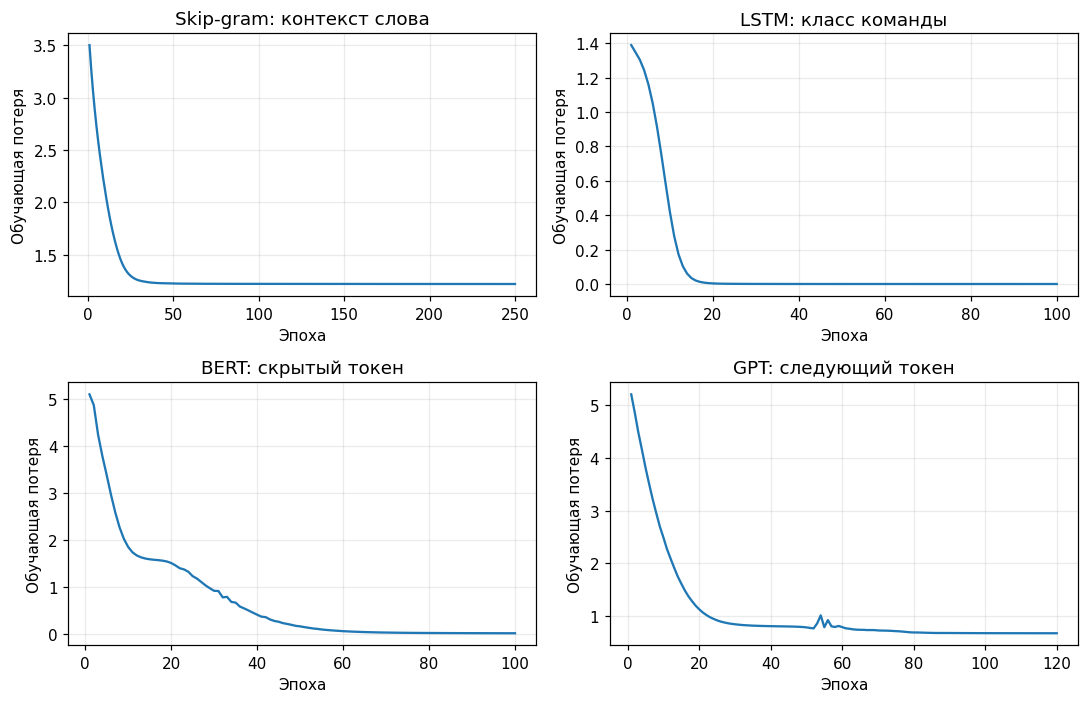

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, history, title in zip(
    axes.ravel(), [skipgram_history, command_history, bert_history, gpt_history],
    ['Skip-gram: контекст слова', 'LSTM: класс команды', 'BERT: скрытый токен', 'GPT: следующий токен'],
):
    ax.plot(history.index, history['Потеря'])
    ax.set_title(title)
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Обучающая потеря')
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Разбор историй обучения.**

- `plt.subplots(2, 2, ...)` создаёт четыре панели. `axes.ravel()` разворачивает их в последовательность. `zip(...)` согласованно перебирает панель, таблицу истории и заголовок; `for` распаковывает тройку значений.
- `.index` содержит эпохи, `history['Потеря']` выбирает их значения. `plot(...)` соединяет записанные точки.
- `set_title(...)`, `set_xlabel(...)` и `set_ylabel(...)` подписывают задачу и оси. `grid(alpha=0.25)` добавляет полупрозрачную сетку. `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

У Skip-gram одно слово имеет много контекстов, у GPT один префикс способен иметь разные продолжения. Эти потери не обязаны стремиться к нулю даже на маленьком корпусе. Для LSTM отдельно показана валидация, а для BERT/GPT — выполнение известных обучающих случаев.

Сохраним токенизатор вместе с моделями и запишем описание опыта. У Word2Vec-подобного примера сохраним входные векторы и отдельный словарь слов; у LSTM — состояние и настройки; у BERT и GPT — локальные каталоги конфигурации и небольших обученных весов.

In [28]:
tokenizer_path = result_dir / 'токенизатор.json'
tokenizer.save(str(tokenizer_path))
word_vectors_path = result_dir / 'Word2Vec_векторы.npy'
np.save(word_vectors_path, word_vectors.numpy())
word_vocabulary_path = result_dir / 'Word2Vec_словарь.json'
word_vocabulary_path.write_text(json.dumps(word_to_id, ensure_ascii=False, indent=2), encoding='utf-8')
lstm_path = result_dir / 'LSTM_команды.pt'
torch.save({'model_state': command_model.state_dict(), 'vocab_size': vocab_size,
            'pad_id': pad_id, 'actions': actions}, lstm_path)
bert_dir = result_dir / 'BERT'
gpt_dir = result_dir / 'GPT'
bert_model.save_pretrained(str(bert_dir))
gpt_model.save_pretrained(str(gpt_dir))

run_description = {
    'версии': {'python': sys.version.split()[0], 'torch': torch.__version__,
               'transformers': transformers.__version__, 'tokenizers': tokenizers.__version__},
    'предобученные_веса_загружались': False,
    'корпус': language_corpus,
    'bpe_словарь': vocab_size,
    'word2vec_слов': len(word_vocabulary),
    'lstm': {'обучение': len(train_commands), 'валидация': len(valid_commands),
             'accuracy': command_accuracy, 'действия': actions},
    'bert': {'режим': 'маленькая MLM, обучена здесь; проверка на обучающих фразах'},
    'gpt': {'режим': 'маленькая causal LM, обучена здесь; один следующий токен',
            'причинность_подтверждена': prefix_unchanged},
    'файлы': {'токенизатор': tokenizer_path.name, 'векторы': word_vectors_path.name,
              'словарь_слов': word_vocabulary_path.name, 'lstm': lstm_path.name,
              'bert': bert_dir.name, 'gpt': gpt_dir.name},
}
description_path = result_dir / 'описание_запуска.json'
description_path.write_text(json.dumps(run_description, ensure_ascii=False, indent=2), encoding='utf-8')
print('Результаты:', result_dir.resolve())

Результаты: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\14_результаты_NLP


**Разбор файлов NLP.**

- Оператор `/` строит пути. `tokenizer.save(str(...))` записывает не только номера словаря, но и настройки токенизации; `str(...)` переводит путь в строку.
- `.numpy()` и `np.save(...)` сохраняют числовую таблицу входных векторов Skip-gram. Её строки читаются через отдельный `word_to_id`; это не BPE-словарь нейросетей. `json.dumps(..., ensure_ascii=False, indent=2)` и `.write_text(..., encoding='utf-8')` записывают русский словарь и описание.
- `.state_dict()` и `torch.save({...}, ...)` сохраняют LSTM вместе с размером словаря, PAD и названиями действий. `save_pretrained(...)` у BERT/GPT записывает **наше текущее обученное состояние и конфигурацию** локально; название метода не означает, что веса были скачаны или что модель стала большой предобученной системой.
- `run_description` — вложенный словарь происхождения данных, версий и границ проверок. `.__version__`, `sys.version.split()[0]`, `len(...)` и `.name` получают версии, размеры и имена путей. `.resolve()` и `print(...)` показывают каталог.

Чтобы повторить вход модели, нужны и веса, и соответствующий токенизатор. Случайная перестановка ID при том же размере словаря способна полностью изменить ответы. Для продолжения обучения Skip-gram потребовалось бы сохранить также выходной слой и настройки; здесь сохранены только его векторы для использования.

Восстановим созданные файлы и сравним выходы с текущими объектами. Загрузка BERT и GPT будет строго локальной. Это завершает проверку, что токенизация и числовые состояния действительно сохраняются, а результаты не зависят от отсутствующего внешнего сервиса.

In [29]:
loaded_tokenizer = Tokenizer.from_file(str(tokenizer_path))
loaded_word_vectors = np.load(word_vectors_path, allow_pickle=False)
lstm_checkpoint = torch.load(lstm_path, map_location='cpu', weights_only=True)
loaded_command_model = CommandLSTM(lstm_checkpoint['vocab_size'], lstm_checkpoint['pad_id'])
loaded_command_model.load_state_dict(lstm_checkpoint['model_state'])
loaded_command_model.eval()
loaded_bert = BertForMaskedLM.from_pretrained(str(bert_dir), local_files_only=True).eval()
loaded_gpt = GPT2LMHeadModel.from_pretrained(str(gpt_dir), local_files_only=True).eval()
with torch.no_grad():
    loaded_command_logits = loaded_command_model(valid_ids, valid_lengths)
    loaded_bert_logits = loaded_bert(input_ids=bert_input_ids, attention_mask=bert_attention_mask).logits
    loaded_gpt_logits = loaded_gpt(input_ids=gpt_prompt_ids, attention_mask=torch.ones_like(gpt_prompt_ids)).logits[0, -1]
restoration_checks = {
    'Токенизатор': loaded_tokenizer.encode(bpe_text).ids == tokenizer.encode(bpe_text).ids,
    'Векторы Skip-gram': np.allclose(loaded_word_vectors, word_vectors.numpy()),
    'LSTM': torch.allclose(loaded_command_logits, valid_command_logits),
    'BERT': torch.allclose(loaded_bert_logits, bert_final_logits, atol=0.000001),
    'GPT': torch.allclose(loaded_gpt_logits, gpt_next_logits, atol=0.000001),
}
display(pd.DataFrame({'Объект': list(restoration_checks), 'Совпадение': list(restoration_checks.values())}))

,Объект,Совпадение
0,Токенизатор,True
1,Векторы Skip-gram,True
2,LSTM,True
3,BERT,True
4,GPT,True


**Разбор восстановления.**

- `Tokenizer.from_file(str(...))` читает сохранённый токенизатор. `np.load(..., allow_pickle=False)` загружает числовой массив без объектов Python.
- `torch.load(..., map_location='cpu', weights_only=True)` читает собственный checkpoint с весами и простыми настройками. `CommandLSTM(...)` создаёт совместимую структуру, `load_state_dict(...)` переносит состояние, `.eval()` задаёт режим ответа.
- `BertForMaskedLM.from_pretrained(...)` и `GPT2LMHeadModel.from_pretrained(...)` здесь получают **локальные пути** и `local_files_only=True`: сеть для загрузки не используется. Веса берутся из предыдущего примера.
- В `torch.no_grad()` вызовы `loaded_command_model(...)`, `loaded_bert(...)` и `loaded_gpt(...)` получают те же входы. `.logits`, `torch.ones_like(...)` и `[0, -1]` выбирают согласованные выходы.
- `.encode(...).ids` сравнивает токенизацию через `==`. `np.allclose(...)`, `.numpy()` и `torch.allclose(..., atol=...)` проверяют числовую близость своих состояний до и после сохранения.
- `restoration_checks` хранит пять логических результатов. `list(...)` получает ключи и `.values()`, `pd.DataFrame(...)` и `display(...)` показывают сводку.

Все пять проверок должны дать `True`. Это проверка воспроизведения собственных объектов, а не проверка общего качества NLP. Файлы и словари используются совместно; небольшие веса не получают дополнительные знания от самого факта сохранения и загрузки.

В сохранённом выполнении все пять сравнений дали `True`: согласованная токенизация и выходы маленьких моделей воспроизвелись после локальной загрузки.

## 8. Как проследить обработку текста

Начинайте с того, как строка превращается в токены и ID. Затем проверьте словарь, служебные токены, настоящие длины и смысл маски в выбранном API. Только после этого читайте форму эмбеддингов и способ обработки последовательности.

Skip-gram изучал статические представления по соседствам. LSTM переносила состояние по порядку команды. Внимание связывало разрешённые позиции, а позиционная информация задавала их расположение. У BERT выходное состояние учитывало правый и левый контекст; GPT сохраняла причинность и предсказывала следующий токен по префиксу.

В этом файле обучены маленькие демонстрационные модели. У LSTM показана отдельная валидация новых шаблонов, у BERT/GPT — работа на известных обучающих связях. Использование больших готовых систем, генерация длинных текстов и промпт-инжиниринг рассматриваются в модуле генеративного ИИ.

### Дополнительные справочные страницы

[Токенизаторы и их компоненты](https://huggingface.co/docs/tokenizers/en/components), [Embedding в PyTorch](https://docs.pytorch.org/docs/2.11/generated/torch.nn.Embedding.html), [MultiheadAttention](https://docs.pytorch.org/docs/2.11/generated/torch.nn.MultiheadAttention.html), [TransformerEncoderLayer](https://docs.pytorch.org/docs/2.11/generated/torch.nn.TransformerEncoderLayer.html). Ссылки справочные: выполнение локального ноутбука не требует их открытия.